In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

In [2]:
import pandas as pd
import time
import math
import numpy as np
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor
import torch
import torch.nn as nn
from src.model.ESN import ESNRegressor

In [3]:
df = pd.read_pickle('data/lorenz_data.pkl')
df.drop(columns=["dt_min", "t_max"], inplace=True)
STRIDE = 100
df_strides = df[ ::STRIDE ].reset_index(drop=True)
df_strides = df_strides[100:].reset_index(drop=True)
rng = np.random.default_rng(0)
torch.manual_seed(0)
np.random.seed(0)
device = torch.cuda.current_device().type if torch.cuda.is_available() else "cpu"
data = df_strides.to_numpy(dtype=np.float32)

In [4]:
from src.data import LorenzWindowViewDataset, ToSkorchXY
from src.util import build_windows, split_indices
from torch.utils.data import DataLoader

TRAIN_RATIO = 0.7
TRAIN_N = math.ceil(2000 / TRAIN_RATIO)
series = df_strides[["x", "y", "z"]].to_numpy(dtype=np.float32) 
dev_series = series[:TRAIN_N]    # (T, 3)
D = dev_series.shape[1]        # 3
WARM, XLEN = 5, 55
windows = build_windows(dev_series, warm_length=WARM, x_length=XLEN)   # (N, W+X+1, 3) view
N = windows.shape[0]
# --- split into *indices* (not materialized arrays) ---
idx = np.arange(N)
train_idx, val_idx = idx[:int(TRAIN_N * TRAIN_RATIO)], idx[int(TRAIN_N * TRAIN_RATIO):]
#print(f"train_idx:\n{train_idx}")

train_idx = train_idx[ : int(TRAIN_N * TRAIN_RATIO) ]
val_idx   = val_idx[   : int(TRAIN_N * (1 - TRAIN_RATIO)) ]
print(f"train_idx.shape (trimmed):\n{train_idx.shape}")
print(f"val_idx.shape (trimmed):\n{val_idx.shape}")

mu  = windows[train_idx].reshape(-1, D).mean(axis=0).astype(np.float32)
sd  = windows[train_idx].reshape(-1, D).std(axis=0).astype(np.float32)
sd  = np.where(sd == 0.0, 1.0, sd)  # guard against zeros



#train_ds = LorenzWindowViewDataset(windows, train_idx, WARM, XLEN, standardize=True, mean=mu, std=sd)
#val_ds  = LorenzWindowViewDataset(windows, val_idx,  WARM, XLEN, standardize=True, mean=mu, std=sd)


#train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,  num_workers=0, pin_memory=False)
#val_loader  = DataLoader(val_ds,  batch_size=4, shuffle=False, num_workers=0, pin_memory=False)


train_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=train_idx, warm_length=WARM, x_length=XLEN,
    standardize=True, mean=mu, std=sd
))
val_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=val_idx, warm_length=WARM, x_length=XLEN,
    standardize=True, mean=mu, std=sd
))


net = NeuralNetRegressor(
    ESNRegressor,
    module__input_size=3,
    module__output_size=3,
    module__reservoir_size=1000,
    module__leak=0.9,
    module__spectral_radius=0.5,
    module__input_scale=1.0,
    module__bias_scale=0.0,
    module__sparsity=0.5,
    module__activation='tanh',
    module__seed=0,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    optimizer__lr=2e-3,
    optimizer__weight_decay=1e-4,   # 0.0001
    max_epochs=25,
    batch_size=32,
    train_split=None,               # no internal val split
    iterator_train__shuffle=False,  # keep time order
    device=device,
    verbose=0,
)

# Train with skorch
#net.fit(train_ds, y=None)

'''
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 1000, 'module__leak': 0.7, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.003, 'module__spectral_radius': 0.7, 'module__sparsity': 0.03, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001, 'module__spectral_radius': 1.0, 'module__sparsity': 0.02, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.001, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.001, 'module__spectral_radius': 0.85, 'module__sparsity': 0.02, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 300, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 16}
'''

train_idx.shape (trimmed):
(2000,)
val_idx.shape (trimmed):
(798,)


"\n{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 1000, 'module__leak': 0.7, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.003, 'module__spectral_radius': 0.7, 'module__sparsity': 0.03, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001

In [5]:
# --- PREREQS (already built earlier) ------------------------------------------
# series:         np.ndarray (T, D) in ORIGINAL scale (float32)
# wins:           sliding_window_view(series, TOTAL=WARM+XLEN+1, axis=0)  -> (N, TOTAL, D)
# train_idx, val_idx: index arrays into wins (contiguous split recommended)
# mu, sd:         per-feature train-only mean/std (float32), shape (D,)
# WARM, XLEN:     warm and x lengths (e.g., 10, 100)

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from skorch import NeuralNetRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error


def ds_to_arrays(ds):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]
        Xs.append(X_i.numpy())
        Ys.append(y_i.numpy())
    return np.stack(Xs, 0), np.stack(Ys, 0)

# standardize ToConcatWarmWindowView outputs on the fly
def ds_to_arrays_std(ds, mu, sd):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]             # original scale tensors
        X_i = (X_i.numpy() - mu) / sd
        y_i = (y_i.numpy() - mu) / sd
        Xs.append(X_i); Ys.append(y_i)
    return np.stack(Xs, 0), np.stack(Ys, 0)

# Return STANDARDIZED predictions
def rollout_std(est, start_window_orig, steps):
    cur = (start_window_orig - mu) / sd
    preds_std = []
    for _ in range(steps):
        y_next_std = est.predict(cur[None, ...]).astype(np.float32)[0]
        preds_std.append(y_next_std)
        cur = np.concatenate([cur[1:], y_next_std[None, :]], axis=0)
    return np.stack(preds_std, axis=0)  # <-- standardized

X_train, y_train = ds_to_arrays(train_ds)
X_val,   y_val   = ds_to_arrays(val_ds)

# fit search exactly as you have it...
net.fit(X_train, y_train)

# original-space metrics
from sklearn.metrics import mean_squared_error
def inv(z): return z * sd + mu




In [6]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error



# 10-step rollout (STANDARDIZED)
abs_i0 = int(val_idx[0])
start_window_orig = windows[abs_i0, :WARM+XLEN, :]
K = 11
preds_std = rollout_std(net, start_window_orig, K)
gt_std = (dev_series[abs_i0 + WARM + XLEN : abs_i0 + WARM + XLEN + K] - mu) / sd


print(f"{K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
print("per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
print("R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))


11-step rollout MSE (std): 0.69889235496521
per-dim MSE: [0.39497203 0.7669811  0.9347239 ]
R² per dim: [0.6426706  0.45265138 0.14472848]


In [7]:
K=11
rollout_stats = []
for start_idx in val_idx:
    if start_idx + WARM + XLEN + K > len(dev_series):
        continue
    start_window_orig = windows[start_idx, :WARM+XLEN, :]
    preds_std = rollout_std(net, start_window_orig, K)
    gt_std = (dev_series[start_idx + WARM + XLEN : start_idx + WARM + XLEN + K] - mu) / sd
    #print(f"Start idx {start_idx}:")
    mean_sq_err = mean_squared_error(gt_std, preds_std)
    r2_scr = r2_score(gt_std, preds_std, multioutput="raw_values")
    rollout_stats.append({
        "start_idx": start_idx,
        "mse": mean_sq_err,
        "r2": r2_scr,
    })
    #print(f"  {K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
    #print("  per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
    #print("  R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))

rollout_stats_df = pd.DataFrame(rollout_stats)

In [8]:
rollout_stats_df = rollout_stats_df.sort_values("start_idx").reset_index(drop=True)
rollout_stats_df.head()

,start_idx,mse,r2
0,2000,0.698892,"[0.6426706, 0.45265138, 0.14472848]"
1,2001,0.581610,"[0.7071748, 0.5647279, 0.38078654]"
2,2002,0.414149,"[0.79214185, 0.6293406, 0.51242846]"
3,2003,0.367445,"[0.7763048, 0.39709008, 0.6648324]"
4,2004,0.656929,"[0.04141122, -1.5260777, 0.65709686]"


In [9]:
rollout_stats_df.describe()

,start_idx,mse
count,788.000000,788.000000
mean,2393.500000,1.055454
std,227.620298,0.746427
min,2000.000000,0.031479
25%,2196.750000,0.465729
50%,2393.500000,0.844615
75%,2590.250000,1.563423
max,2787.000000,3.962379


In [10]:
rollout_stats_df["mse"].mean()

1.055453781950935

In [11]:
print(X_train.shape)

(2000, 60, 3)


In [12]:
rollout_preds = rollout_std(net, start_window_orig, int(TRAIN_N * (1 - TRAIN_RATIO)))

    

In [13]:
rollout_preds_df = pd.DataFrame(rollout_preds, columns=["x", "y", "z"])
rollout_preds_df.head()

,x,y,z
0,-0.587563,-0.397986,0.008785
1,-0.564813,-0.589968,-0.239163
2,-0.806601,-1.112566,-0.097691
3,-1.364561,-1.711632,0.558685
4,-1.666823,-1.471317,1.019519


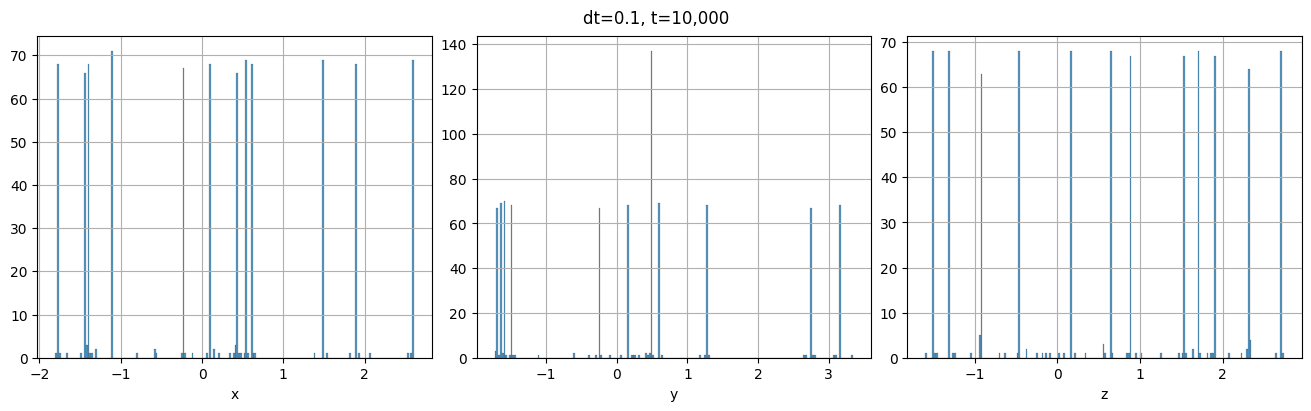

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = {0: 'x', 1: 'y', 2: 'z'}
fig, axs = plt.subplots(1, 3, layout='constrained', figsize=(13, 4))
for i, arr in enumerate([rollout_preds_df['x'], rollout_preds_df['y'], rollout_preds_df['z']]):
    sns.histplot(arr, bins=200, ax=axs[i])
    axs[i].set_xlabel(f'{labels[i]}')
    axs[i].set_ylabel('')
    axs[i].grid(True)
fig.suptitle(f'dt={0.1}, t={10_000:,}')
plt.show()

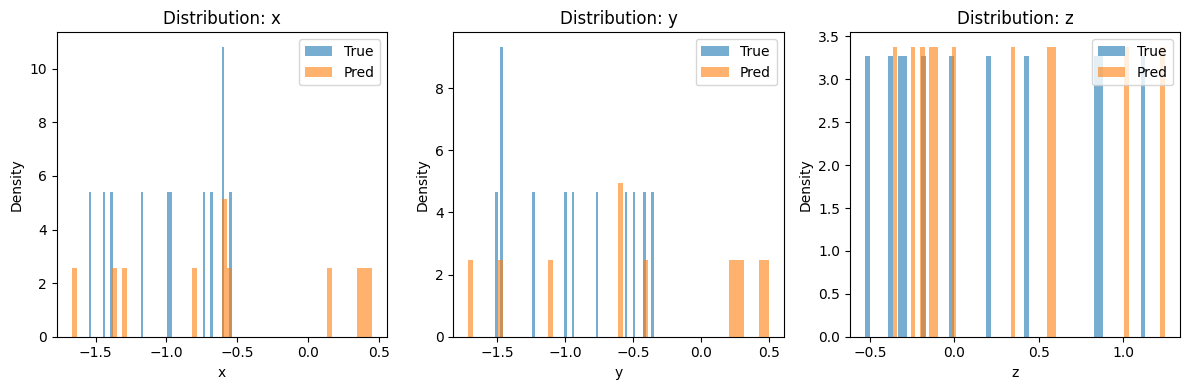

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# assume y_pred and y_true are in ORIGINAL scale, shape (N, 3)
axes = ['x', 'y', 'z']

plt.figure(figsize=(12, 4))
for i, a in enumerate(axes):
    plt.subplot(1, 3, i+1)
    plt.hist(gt_std[:, i], bins=60, alpha=0.6, label='True', density=True)
    plt.hist(preds_std[:, i], bins=60, alpha=0.6, label='Pred', density=True)
    plt.title(f'Distribution: {a}')
    plt.xlabel(a)
    plt.ylabel('Density')
    plt.legend()
plt.tight_layout()
plt.show()

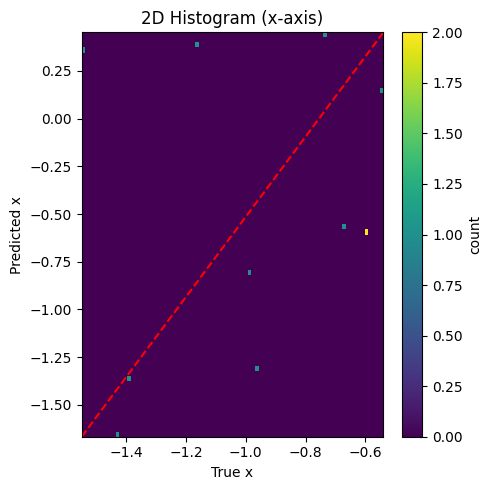

In [16]:
plt.figure(figsize=(5,5))
plt.hist2d(gt_std[:,0], preds_std[:,0], bins=80, cmap='viridis')
plt.xlabel("True x")
plt.ylabel("Predicted x")
plt.title("2D Histogram (x-axis)")
plt.colorbar(label='count')
plt.plot([gt_std[:,0].min(), gt_std[:,0].max()],
         [preds_std[:,0].min(), preds_std[:,0].max()], 'r--')
plt.tight_layout()
plt.show()

In [17]:
abs_i0 = int(val_idx[0])
start_window_orig = windows[abs_i0, :WARM+XLEN, :]
K = 100
preds_std = rollout_std(net, start_window_orig, K)
gt_std = (dev_series[abs_i0 + WARM + XLEN : abs_i0 + WARM + XLEN + K] - mu) / sd


print(f"{K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
print("per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
print("R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))

100-step rollout MSE (std): 2.6494219303131104
per-dim MSE: [2.0966947 2.6556735 3.1958976]
R² per dim: [-1.1457582 -1.6108532 -1.9782419]


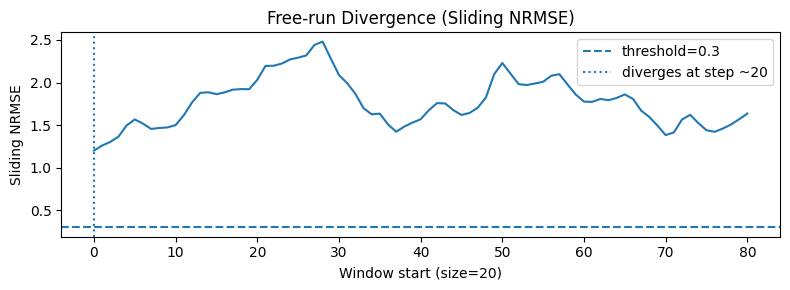


=== Divergence diagnostics ===
Aligned length : 100

Pre-divergence metrics:
     K = 20.0000
   MSE = 1.6628
  RMSE = 1.2895
   MAE = 0.9738
    R2 = -0.5366

Post-divergence metrics:
     K = 80.0000
   MSE = 2.8961
  RMSE = 1.7018
   MAE = 1.3728
    R2 = -1.9432


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rollout_diagnostics(y_true, y_pred, window=200, threshold=0.2, plot=True):
    """
    y_true: (K, D) ground truth segment aligned to the rollout start
    y_pred: (K, D) model rollout (same scale as y_true)
    window: sliding window length for NRMSE
    threshold: divergence threshold on NRMSE
    plot: whether to draw the NRMSE curve and threshold line

    Returns: dict with
      - 'aligned_len', 'diverges_at' (int or None), 'nrmse_series' (np.array)
      - 'pre'  : {'K','MSE','RMSE','MAE','R2'}  (if divergence found, up to divergence; else full)
      - 'post' : {'K','MSE','RMSE','MAE','R2'}  (if divergence found)
    """
    # --- align lengths safely ---
    K = min(len(y_true), len(y_pred))
    if K == 0:
        raise ValueError("Empty y_true/y_pred after alignment.")
    yt = np.asarray(y_true[:K], dtype=np.float32)
    yp = np.asarray(y_pred[:K], dtype=np.float32)

    # --- compute sliding NRMSE ---
    W = min(window, K)
    nrmse = []
    for s in range(0, K - W + 1):
        seg_t = yt[s:s+W]
        seg_p = yp[s:s+W]
        rmse = np.sqrt(np.mean((seg_t - seg_p)**2))
        denom = np.std(seg_t) + 1e-8
        nrmse.append(rmse / denom)
    nrmse = np.array(nrmse)  # length K-W+1

    # --- find divergence point (index in rollout steps) ---
    diverges_at = None
    if nrmse.size > 0:
        hits = np.where(nrmse > threshold)[0]
        if hits.size > 0:
            # convert window start index -> last index included in that window
            diverges_at = int(hits[0] + W)  # first step AFTER a window that exceeded threshold

    # --- helper to compute summary metrics over a slice ---
    def _metrics(a, b):
        mse = float(mean_squared_error(a, b))
        rmse = float(np.sqrt(mse))
        mae = float(mean_absolute_error(a, b))
        r2  = float(r2_score(a, b))
        return dict(K=len(a), MSE=mse, RMSE=rmse, MAE=mae, R2=r2)

    # --- pre/post segments ---
    stats_pre = _metrics(yt[:diverges_at], yp[:diverges_at]) if diverges_at else _metrics(yt, yp)
    stats_post = None
    if diverges_at and diverges_at < K:
        stats_post = _metrics(yt[diverges_at:], yp[diverges_at:])

    # --- optional plot ---
    if plot and nrmse.size > 0:
        plt.figure(figsize=(8,3))
        plt.plot(nrmse)
        plt.axhline(threshold, linestyle='--', label=f'threshold={threshold}')
        if diverges_at:
            # show vertical line at the window index corresponding to divergence
            plt.axvline(diverges_at - W, linestyle=':', label=f'diverges at step ~{diverges_at}')
        plt.xlabel(f"Window start (size={W})")
        plt.ylabel("Sliding NRMSE")
        plt.title("Free-run Divergence (Sliding NRMSE)")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return dict(
        aligned_len=K,
        diverges_at=diverges_at,      # int or None
        nrmse_series=nrmse,
        pre=stats_pre,
        post=stats_post,
        window=W,
        threshold=threshold,
    )

# Assuming you already computed:
# long_preds: (k, D) rollout (scaled or original)
# y_true    : (k, D) aligned ground truth in the SAME scale

diag = rollout_diagnostics(gt_std, preds_std, window=20, threshold=0.3, plot=True)

print("\n=== Divergence diagnostics ===")
print(f"Aligned length : {diag['aligned_len']}")
#print(f"Diverges at    : {diag['diverges_at']} steps (≈ {diag['diverges_at']/len(gt_std)*100:.1f}% of rollout)")
print("\nPre-divergence metrics:")
for k,v in diag['pre'].items():
    print(f"  {k:>4s} = {v:.4f}" if isinstance(v,(int,float)) else f"  {k}: {v}")

if diag['post']:
    print("\nPost-divergence metrics:")
    for k,v in diag['post'].items():
        print(f"  {k:>4s} = {v:.4f}" if isinstance(v,(int,float)) else f"  {k}: {v}")
else:
    print("\n(No post-divergence segment — model stayed below threshold.)")



In [19]:
def step_wise_mse(y_true, y_pred):
    """
    y_true, y_pred: (K, D) arrays aligned from rollout start
    Returns: list of MSE per step index
    """
    K = min(len(y_true), len(y_pred))
    mse_list = []
    for k in range(1, K):
        mse_k = mean_squared_error(y_true[:k], y_pred[:k])
        mse_list.append(mse_k)
    return mse_list

LONG_K = 44
THRESHOLD = 0.3
long_rollout_diag = []
curves = []

for start_idx in val_idx:
    if start_idx + WARM + XLEN + LONG_K > len(dev_series):
        continue
    start_window_orig = windows[start_idx, :WARM+XLEN, :]
    preds_std = rollout_std(net, start_window_orig, LONG_K)
    gt_std = (dev_series[start_idx + WARM + XLEN : start_idx + WARM + XLEN + LONG_K] - mu) / sd
    mse = step_wise_mse(gt_std, preds_std)
    curves.append({start_idx: mse})
#long_rollout_diag_df = pd.DataFrame(long_rollout_diag)

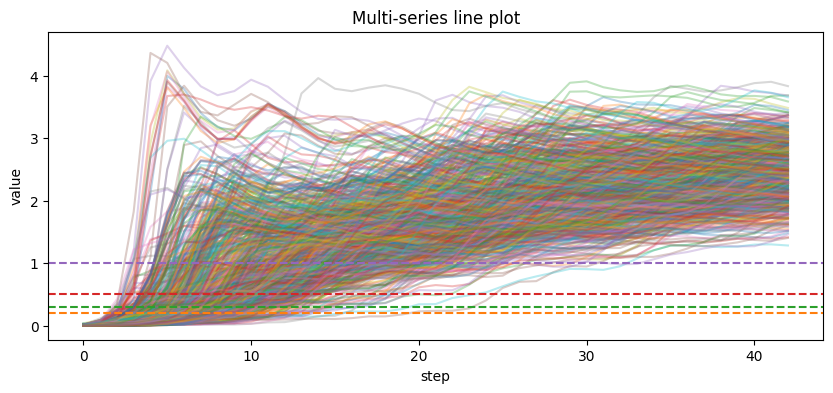

In [20]:
curve_dic = {}
for c in curves:
    i = 0
    for k,v in c.items():
        pass
    curve_dic[k] = v
df_wide = pd.DataFrame(curve_dic)
df_wide.index.name = "step"
# (optional) sort columns numerically
df_wide = df_wide[sorted(df_wide.columns)]

# 3) Plot multiple lines (one per series key)
ax = df_wide.plot(legend=False, figsize=(10, 4), alpha=0.3)
plt.axhline(0.2, linestyle='--', color='C1', label=f'0.2')
plt.axhline(THRESHOLD, linestyle='--', color='C2', label=f'{THRESHOLD}')
plt.axhline(0.5, linestyle='--', color='C3', label=f'0.5')
plt.axhline(1.0, linestyle='--', color='C4', label=f'1.0')
ax.set_xlabel("step")
ax.set_ylabel("value")
ax.set_title("Multi-series line plot")
plt.show()

In [21]:
df_wide.head()

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2745,2746,2747,2748,2749,2750,2751,2752,2753,2754
step,,,,,,,,,,,,,,,,,,,,,
0,0.003004,0.013321,0.011231,0.007728,0.005327,0.011610,0.004032,0.000019,0.001247,0.002185,...,0.015275,0.005803,0.004741,0.005368,0.014562,0.003006,0.000429,0.001463,0.001161,0.000742
1,0.037346,0.075688,0.033209,0.010961,0.014567,0.048409,0.014585,0.000305,0.008222,0.011003,...,0.058004,0.017187,0.005195,0.036143,0.061061,0.006941,0.002794,0.006875,0.002469,0.001660
2,0.168414,0.101257,0.026438,0.011016,0.054178,0.111805,0.031836,0.003351,0.015653,0.012748,...,0.041222,0.014453,0.014927,0.121165,0.098726,0.006197,0.006771,0.007504,0.002319,0.006977
3,0.191419,0.081782,0.027673,0.029159,0.125510,0.183892,0.070985,0.008831,0.014017,0.015651,...,0.040979,0.023170,0.060322,0.166772,0.116077,0.010650,0.006142,0.008625,0.009252,0.022696
4,0.197443,0.087825,0.059560,0.065384,0.192804,0.279624,0.124310,0.009418,0.022080,0.059361,...,0.077395,0.063025,0.098933,0.186542,0.166685,0.017782,0.008734,0.030800,0.032720,0.036397


In [22]:
df = df_wide.T
df = df.reset_index().rename(columns={'index': 'start'})
df = df.rename(columns={df.columns[0]: 'start'})

# Make sure the remaining columns are the step numbers (ints)
step_cols = [c for c in df.columns if c != 'start']
try:
    steps = pd.Index(step_cols).astype(int)            # if they already look like "1","2",...
    df.columns = ['start'] + steps.tolist()
except Exception:
    # fall back to 1..N
    df.columns = ['start'] + list(range(1, len(step_cols)+1))

# Long form: start, step, mse
long = df.melt(id_vars='start', var_name='step', value_name='mse')
long['step'] = long['step'].astype(int)

# Optional: clip or filter values (e.g., only show MSE <= 2)
#long = long[long['mse'] <= 2]
long.head()

,start,step,mse
0,2000,0,0.003004
1,2001,0,0.013321
2,2002,0,0.011231
3,2003,0,0.007728
4,2004,0,0.005327


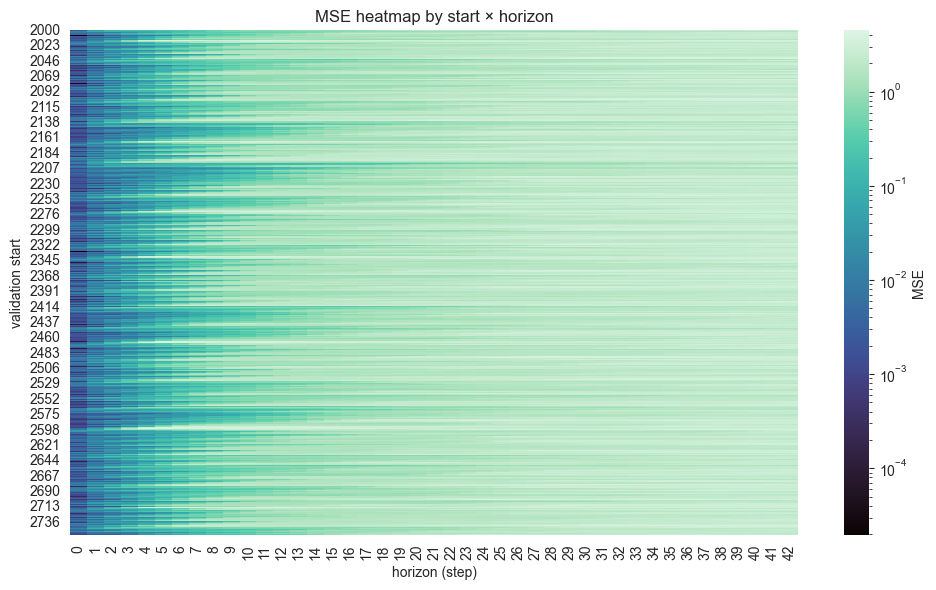

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm   # helpful for wide error ranges

pivot = long.pivot_table(index='start', columns='step', values='mse', aggfunc='mean')
sns.set_style("whitegrid")
plt.figure(figsize=(10,6))
ax = sns.heatmap(
    pivot.sort_index(),                 # keep starts in order
    cmap='mako',                        # any seaborn palette
    cbar_kws={'label': 'MSE'},
    norm=LogNorm()                      # remove if you prefer linear color
)
ax.set_xlabel('horizon (step)')
ax.set_ylabel('validation start')
ax.set_title('MSE heatmap by start × horizon')
plt.tight_layout()
plt.show()


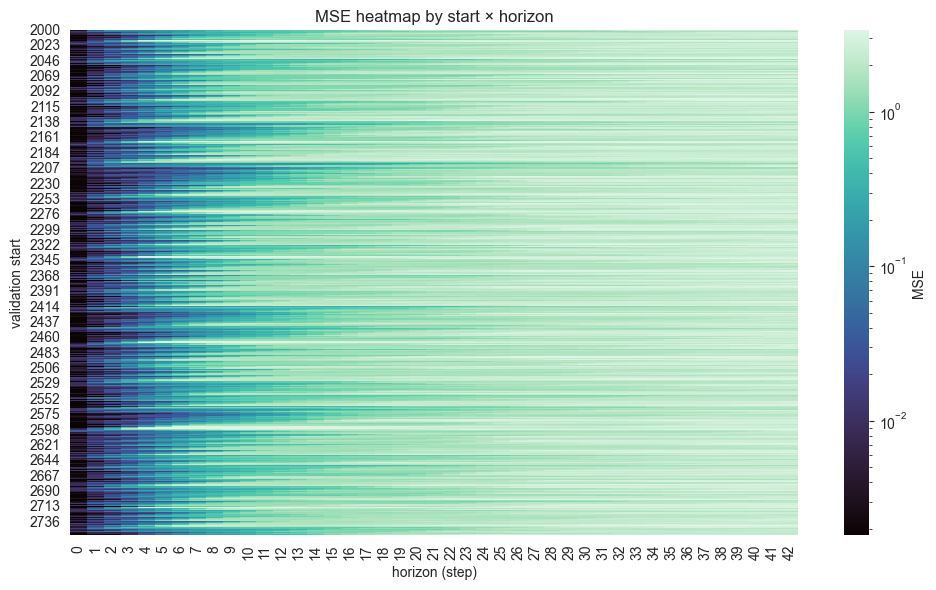

In [24]:
import numpy as np
from matplotlib.colors import LogNorm
import seaborn as sns, matplotlib.pyplot as plt

M = pivot.sort_index().to_numpy()
eps = 1e-12
lo = np.nanpercentile(M[M>0], 1)
hi = np.nanpercentile(M, 99)

plt.figure(figsize=(10,6))
ax = sns.heatmap(
    pivot.sort_index(),
    cmap='mako',                               # high-contrast sequential
    norm=LogNorm(vmin=max(lo, eps), vmax=hi),  # tighten range for contrast
    cbar_kws={'label':'MSE'}
)
ax.set(xlabel='horizon (step)', ylabel='validation start', title='MSE heatmap by start × horizon')
plt.tight_layout()
plt.show()


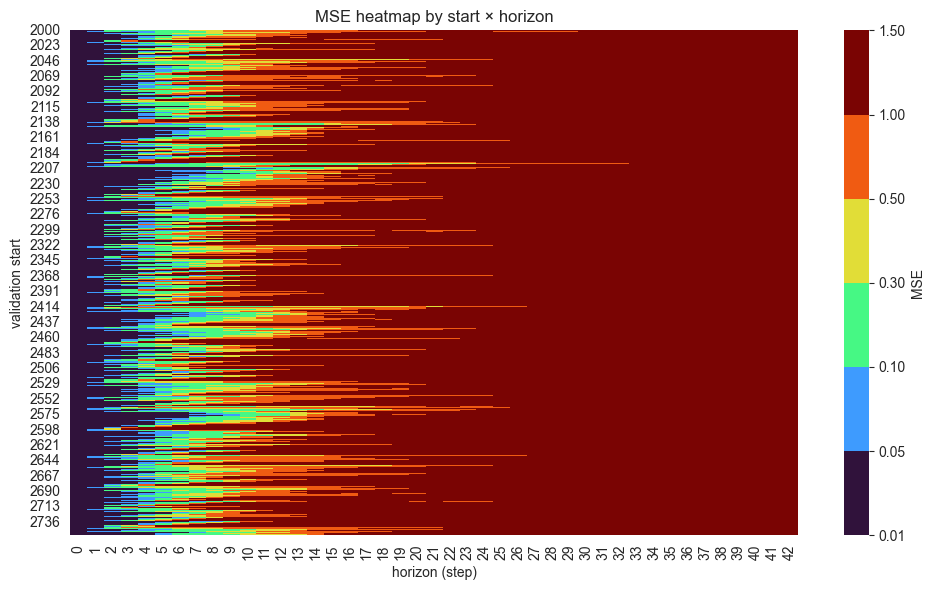

In [25]:
from matplotlib.colors import BoundaryNorm
import matplotlib.pyplot as plt

bounds = [1e-2, 5e-2, 1e-1, 3e-1, 5e-1, 1, 1.5]
cmap   = plt.get_cmap('turbo', len(bounds)-1)   # discrete steps
norm   = BoundaryNorm(bounds, ncolors=cmap.N, clip=True)

plt.figure(figsize=(10,6))
ax = sns.heatmap(
    pivot.sort_index(),
    cmap=cmap, norm=norm,
    cbar_kws={'ticks': bounds, 'label':'MSE'}
)
ax.set(xlabel='horizon (step)', ylabel='validation start', title='MSE heatmap by start × horizon')
plt.tight_layout(); plt.show()


In [26]:
long.head()

,start,step,mse
0,2000,0,0.003004
1,2001,0,0.013321
2,2002,0,0.011231
3,2003,0,0.007728
4,2004,0,0.005327


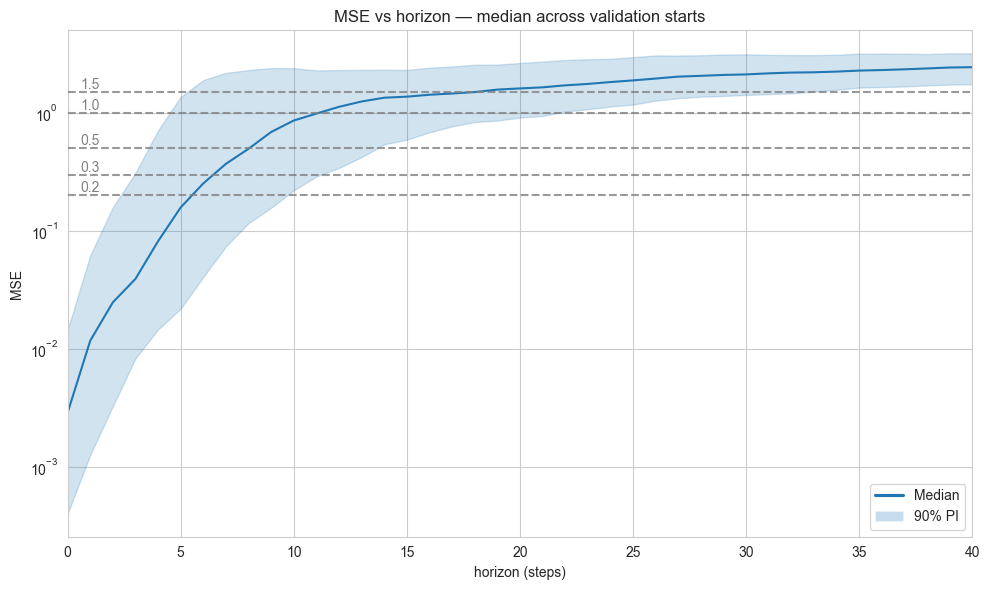

In [27]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

sns.set_style("whitegrid")
#plt.figure(figsize=(10,6))
fig, ax = plt.subplots(figsize=(10,6))
sns.lineplot(
    data=long, x='step', y='mse',
    estimator='median', errorbar=('pi', 90), 
)
plt.yscale('log')                           # MSE is positive; log shows growth clearly
plt.title('MSE vs horizon — median across validation starts')
plt.xlabel('horizon (steps)')
plt.ylabel('MSE')
levels = [0.2, 0.3, 0.5, 1.0, 1.5]
for i, y in enumerate(levels):
    ax.axhline(y, linestyle='--', linewidth=1.5, color='gray',
               alpha=0.8, zorder=5, label=f'{y}')
    ax.text(1.005, y, f'{y}', ha='center', va='bottom', color='gray', fontsize=10)
ax.set_xlim(0, 40)
# --- Legend handles ---
line_color = ax.lines[0].get_color()
line_handle   = Line2D([0], [0], color=line_color, lw=2.25, label='Median')
band_handle   = mpatches.Patch(facecolor=line_color, alpha=0.25, label='90% PI')

ax.legend(handles=[line_handle, band_handle],
          loc='lower right', frameon=True, title=None)

plt.tight_layout(); plt.show()


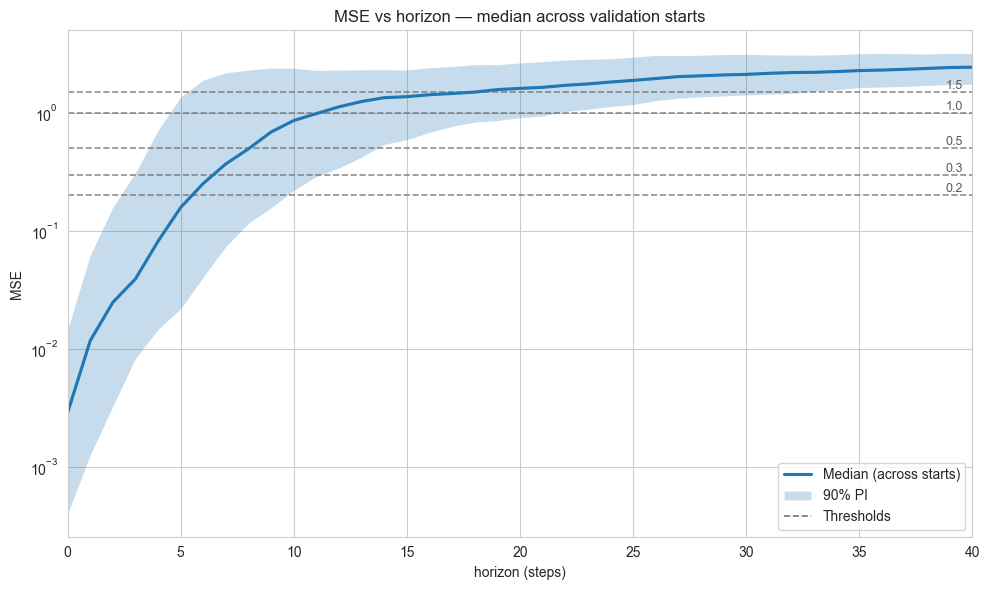

In [28]:
import seaborn as sns, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

levels = [0.2, 0.3, 0.5, 1.0, 1.5]

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=long, x='step', y='mse',
    estimator='median',
    errorbar=('pi', 90),                 # central 90% interval
    err_kws=dict(alpha=0.25, linewidth=0),
    linewidth=2.25, label='Median (across starts)', ax=ax
)

ax.set_yscale('log')
ax.set(title='MSE vs horizon — median across validation starts',
       xlabel='horizon (steps)', ylabel='MSE')
ax.set_xlim(0, 40)

# threshold lines (no labels, we’ll add a single proxy in legend)
for y in levels:
    ax.axhline(y, ls='--', lw=1.2, color='0.45', alpha=0.8, zorder=1)
    ax.text(0.99, y, f'{y}', transform=ax.get_yaxis_transform(),
            ha='right', va='bottom', color='0.35', fontsize=9)

# --- Legend handles ---
line_color = ax.lines[0].get_color()
line_handle   = Line2D([0], [0], color=line_color, lw=2.25, label='Median (across starts)')
band_handle   = mpatches.Patch(facecolor=line_color, alpha=0.25, label='90% PI')
thresh_handle = Line2D([0], [0], color='0.45', lw=1.2, ls='--', label='Thresholds')

ax.legend(handles=[line_handle, band_handle, thresh_handle],
          loc='lower right', frameon=True, title=None)

plt.tight_layout(); plt.show()


In [29]:
diamonds = sns.load_dataset("diamonds")
diamonds.head() 

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [30]:
long.head()

,start,step,mse
0,2000,0,0.003004
1,2001,0,0.013321
2,2002,0,0.011231
3,2003,0,0.007728
4,2004,0,0.005327


In [31]:
plt.show()

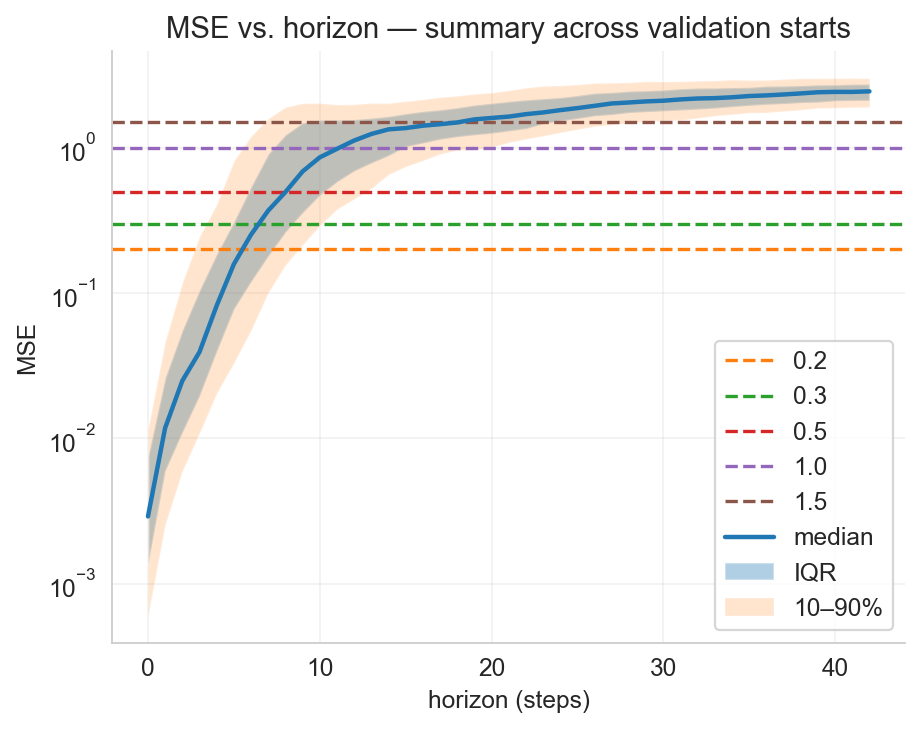

In [32]:
steps = df_wide.index.values
arr   = df_wide.values  # shape (n_steps, n_starts)
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 160,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.antialiased": True,
    "path.simplify": True,
    "path.simplify_threshold": 0.4,
})
med = np.median(arr, axis=1)
q25 = np.quantile(arr, 0.25, axis=1); q75 = np.quantile(arr, 0.75, axis=1)
q10 = np.quantile(arr, 0.10, axis=1); q90 = np.quantile(arr, 0.90, axis=1)

plt.figure()
plt.axhline(0.2, linestyle='--', color='C1', label=f'0.2')
plt.axhline(THRESHOLD, linestyle='--', color='C2', label=f'{THRESHOLD}')
plt.axhline(0.5, linestyle='--', color='C3', label=f'0.5')
plt.axhline(1.0, linestyle='--', color='C4', label=f'1.0')
plt.axhline(1.5, linestyle='--', color='C5', label=f'1.5')
plt.plot(steps, med, lw=2, label="median")
plt.fill_between(steps, q25, q75, alpha=0.35, label="IQR")
plt.fill_between(steps, q10, q90, alpha=0.20, label="10–90%")
plt.yscale("log")  # optional, often helpful for heavy-tailed MSE
plt.xlabel("horizon (steps)"); plt.ylabel("MSE")
plt.title("MSE vs. horizon — summary across validation starts"); plt.legend(); plt.show()


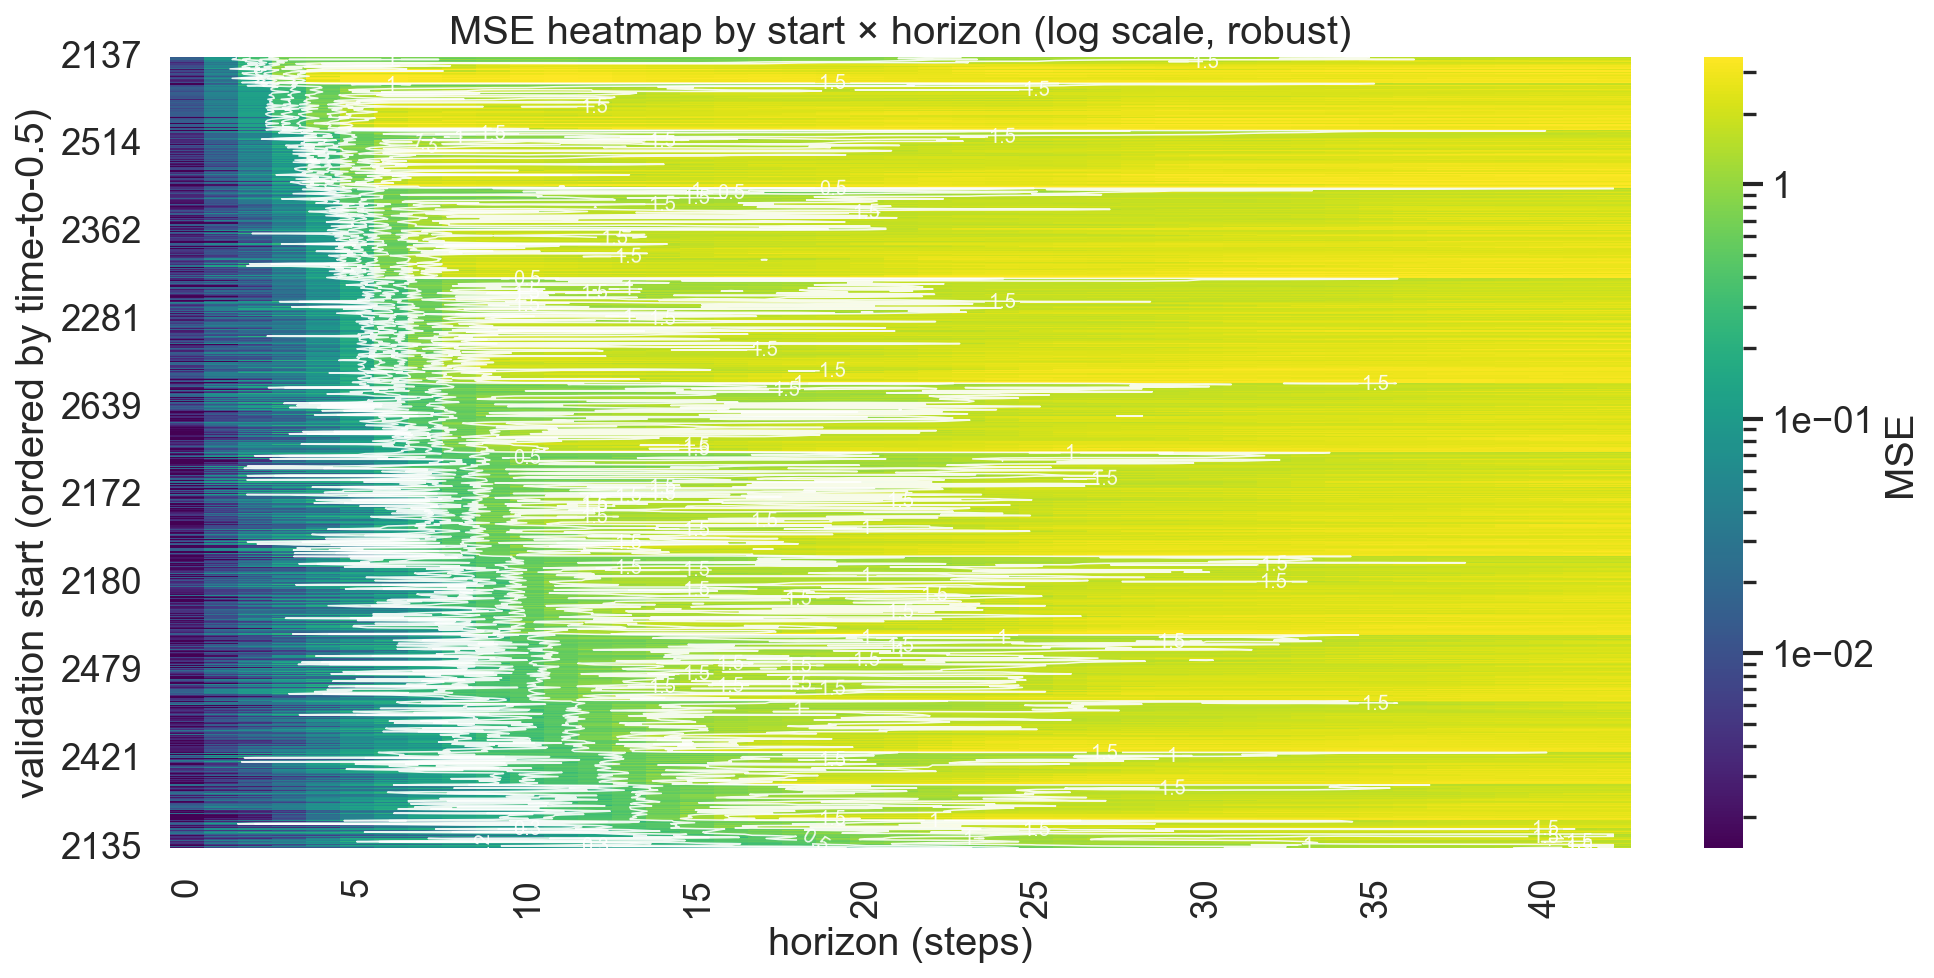

In [33]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, LogFormatter

# --- build the matrix (your code) ---
pivot = long.pivot_table(index='start', columns='step', values='mse', aggfunc='mean')
steps  = pivot.columns.to_numpy()
starts = pivot.index.to_numpy()
M      = pivot.to_numpy()

# --- optional gentle smoothing along the horizon axis to reduce blockiness ---
try:
    from scipy.ndimage import gaussian_filter1d
    M = gaussian_filter1d(M, sigma=0.5, axis=1, mode='nearest')
except Exception:
    pass  # scipy not available -> skip smoothing

# --- order rows by "time-to-threshold" (earliest step crossing tau), then by mean ---
tau = 0.5
n_steps = M.shape[1]
cross = np.full(M.shape[0], n_steps + 1)
ge = M >= tau
has_hit = ge.any(axis=1)
cross[has_hit] = ge.argmax(axis=1)[has_hit]
order = np.lexsort((M.mean(axis=1), cross))
M_plot      = M[order]
starts_ord  = starts[order]

# --- robust log color scaling to avoid outlier washout ---
vmin = max(np.nanpercentile(M_plot, 0.5), 1e-8)
vmax = np.nanpercentile(M_plot, 99.5)
norm = LogNorm(vmin=vmin, vmax=vmax)

# --- plot ---
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
hm = sns.heatmap(
    M_plot,
    cmap="viridis",
    norm=norm,
    cbar_kws={"label": "MSE"},
    xticklabels=steps,           # show true horizon values
    yticklabels=starts_ord,      # show original start indices (reordered)
    ax=ax
)

# thin out tick density for readability
ax.set_xticks(np.arange(0, len(steps), 5) + 0.5)
ax.set_xticklabels(steps[::5])
yticks = np.linspace(0, len(starts_ord) - 1, 10).astype(int)
ax.set_yticks(yticks + 0.5)
ax.set_yticklabels(starts_ord[yticks])

ax.set_xlabel("horizon (steps)")
ax.set_ylabel("validation start (ordered by time-to-0.5)")
ax.set_title("MSE heatmap by start × horizon (log scale, robust)")

# nicer log ticks on the colorbar
cbar = hm.collections[0].colorbar
cbar.locator = LogLocator(base=10)
cbar.formatter = LogFormatter(base=10)
cbar.update_ticks()

# --- optional: white contour lines at key thresholds ---
levels = [0.2, 0.3, 0.5, 1.0, 1.5]
xx, yy = np.meshgrid(np.arange(M_plot.shape[1]) + 0.5, np.arange(M_plot.shape[0]) + 0.5)
CS = ax.contour(xx, yy, M_plot, levels=levels, colors='w', linewidths=0.7, alpha=0.9)
ax.clabel(CS, inline=True, fmt=lambda v: f"{v:g}", fontsize=9)

plt.show()


In [34]:
len(curves)

755